# Importing Libraries And Getting Data

In [2]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


df=pd.read_csv(r"C:\Users\aumee\Documents\Layoffs_Data_Analysis\data\raw\raw_layoff.csv")

# Load Dataset and Cleanup 

In [3]:

# Industry cleanup
def change_industry(x):
    if isinstance(x, str) and 'Crypto' in x:
        return 'Crypto'
    return x

df['industry'] = df['industry'].apply(change_industry)

# Stage cleanup
def change_stage(x):
    if isinstance(x, str) and 'Unknown' in x:
        return np.nan
    return x

df['stage'] = df['stage'].apply(change_stage)

# Date conversion
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Save cleaned dataset
df.to_csv("../data/cleaned/layoffs_cleaned.csv", index=False)

# Dataset Overview

In [4]:
print(df.shape)
df.info()
df.describe()

(2361, 9)
<class 'pandas.DataFrame'>
RangeIndex: 2361 entries, 0 to 2360
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   company                2361 non-null   str           
 1   location               2361 non-null   str           
 2   industry               2357 non-null   str           
 3   total_laid_off         1621 non-null   float64       
 4   percentage_laid_off    1576 non-null   float64       
 5   date                   2360 non-null   datetime64[us]
 6   stage                  1962 non-null   str           
 7   country                2361 non-null   str           
 8   funds_raised_millions  2152 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(5)
memory usage: 166.1 KB


,total_laid_off,percentage_laid_off,date,funds_raised_millions
count,1621.000000,1576.000000,2360,2152.000000
mean,238.358421,0.257917,2022-02-02 23:38:02.033898,822.454134
min,3.000000,0.000000,2020-03-11 00:00:00,0.000000
25%,36.000000,0.100000,2020-08-19 18:00:00,50.000000
50%,80.000000,0.170000,2022-08-01 00:00:00,156.500000
75%,180.000000,0.300000,2022-12-01 00:00:00,445.000000
max,12000.000000,1.000000,2023-03-06 00:00:00,121900.000000
std,769.718801,0.255575,NaN,5593.961626


# Missing Values Analysis

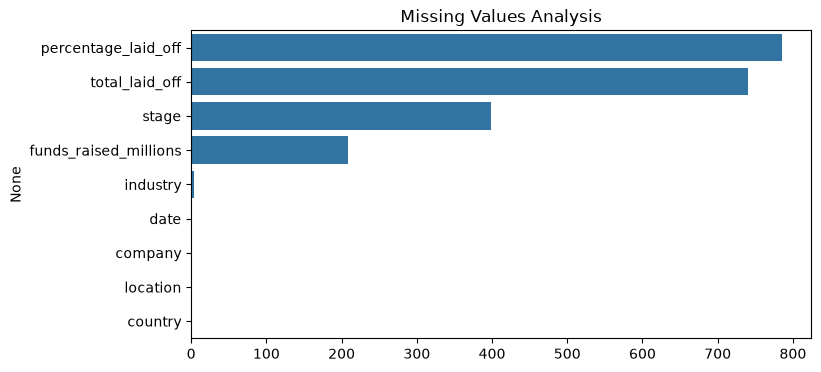

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)

plt.figure(figsize=(8,4))
sns.barplot(
    x=missing.values,
    y=missing.index
)

plt.title("Missing Values Analysis")
plt.show()



# EDA (Exploratory Data Analysis)

## How has the percentage of layoffs varied across different industries?

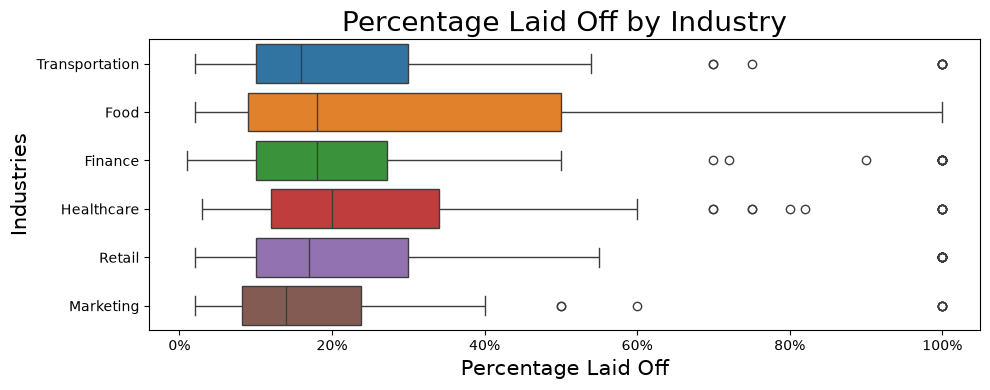

In [6]:
# Top 6 industries
top_industries = df['industry'].value_counts().head(6).index

# Filter data
df_filtered = df[df['industry'].isin(top_industries)].copy()

# Ensure percentage_laid_off is numeric
df_filtered['percentage_laid_off'] = pd.to_numeric(
    df_filtered['percentage_laid_off'],
    errors='coerce'
)

# Remove null values
df_filtered = df_filtered.dropna(
    subset=['percentage_laid_off', 'industry']
)

# Plot
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df_filtered,
    x='percentage_laid_off',
    y='industry',
    hue='industry',
    legend=False
)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'{x:.0%}')
)

plt.ylabel('Industries', fontsize=15)
plt.xlabel('Percentage Laid Off', fontsize=15)
plt.title('Percentage Laid Off by Industry', fontsize=20)

plt.tight_layout()

plt.show()

## How have layoffs varied throughout the year?

C:\Users\aumee\AppData\Local\Temp\ipykernel_21612\810453696.py:16: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  plot4['month_name'] = pd.to_datetime(


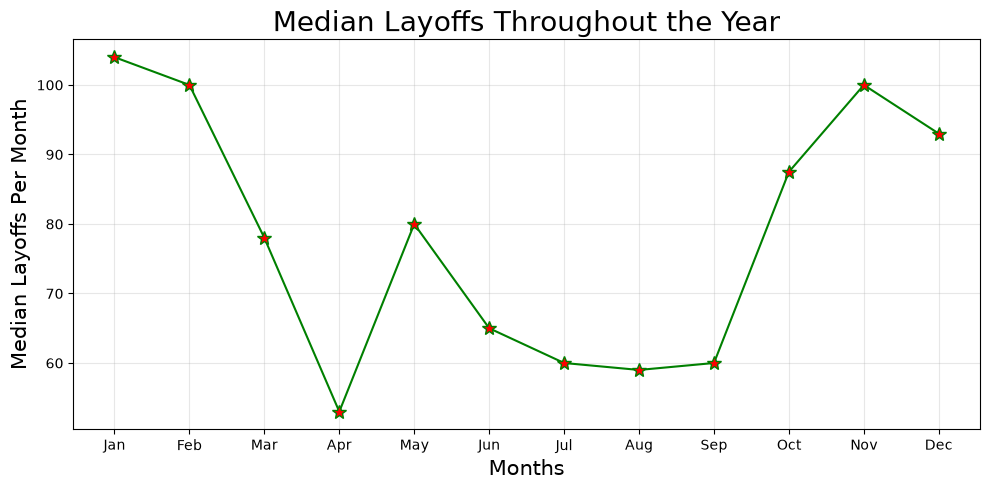

In [7]:
# Ensure date column is datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Extract month
df['month'] = df['date'].dt.month

# Median layoffs by month
plot4 = (
    df.groupby('month')['total_laid_off']
      .median()
      .reset_index()
      .sort_values('month')
)

# Month names
plot4['month_name'] = pd.to_datetime(
    plot4['month'], format='%m'
).dt.strftime('%b')

# Plot
plt.figure(figsize=(10, 5))

plt.plot(
    plot4['month_name'],
    plot4['total_laid_off'],
    color='green',
    marker='*',
    markerfacecolor='red',
    markersize=10
)

plt.title('Median Layoffs Throughout the Year', fontsize=20)
plt.ylabel('Median Layoffs Per Month', fontsize=15)
plt.xlabel('Months', fontsize=15)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## How have companies raised funds from different sources?

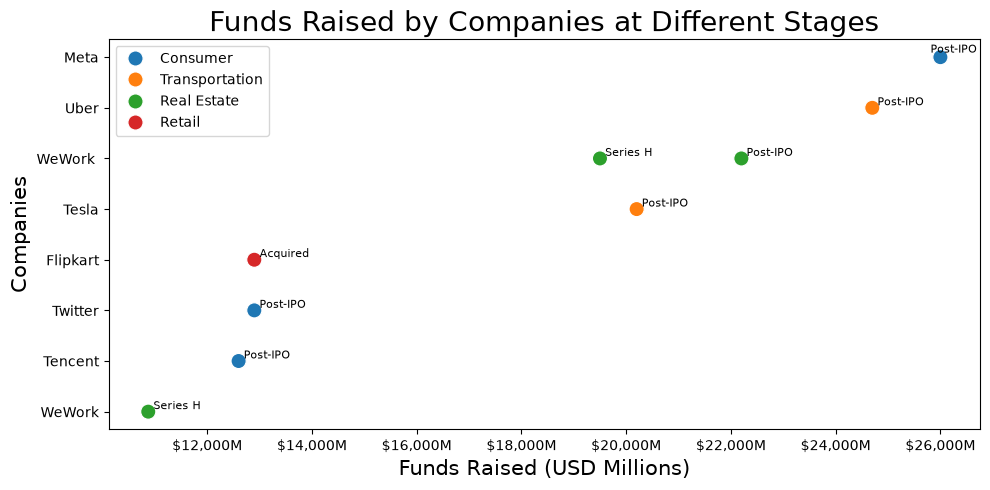

In [8]:
from adjustText import adjust_text
import matplotlib.pyplot as plt
import seaborn as sns

plot5 = (
    df.groupby(['company', 'stage'])['funds_raised_millions']
      .median()
      .sort_values(ascending=False)
      .head(10)
      .iloc[1:]
      .reset_index(name='Funds')
)

temp_df = df[['company', 'industry']].drop_duplicates()

final_plot = plot5.merge(
    temp_df,
    on='company',
    how='left'
)

plt.figure(figsize=(10, 5))

ax = sns.scatterplot(
    data=final_plot,
    x='Funds',
    y='company',
    hue='industry',
    s=120
)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'${x:,.0f}M')
)

texts = []

companies = final_plot['company'].unique()

for _, row in final_plot.iterrows():
    y_pos = list(companies).index(row['company'])

    texts.append(
        ax.text(
            row['Funds'],
            y_pos,
            row['stage'],
            fontsize=8
        )
    )

adjust_text(texts)

plt.legend(loc='upper left')
plt.ylabel('Companies', fontsize=15)
plt.xlabel('Funds Raised (USD Millions)', fontsize=15)
plt.title('Funds Raised by Companies at Different Stages', fontsize=20)

plt.tight_layout()
plt.show()

## Top 10 Countries by Total Layoffs

C:\Users\aumee\AppData\Local\Temp\ipykernel_21612\4163278037.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


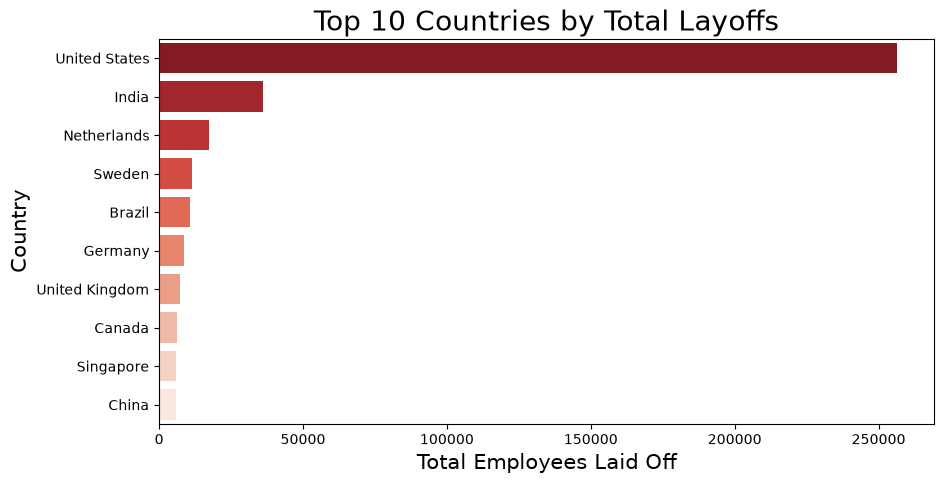

In [9]:
country_layoffs = (
    df.groupby('country')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10,5))

sns.barplot(
    data=country_layoffs,
    x='total_laid_off',
    y='country',
    palette='Reds_r'
)

plt.title('Top 10 Countries by Total Layoffs', fontsize=20)
plt.xlabel('Total Employees Laid Off', fontsize=15)
plt.ylabel('Country', fontsize=15)

plt.show()

## Top Industries by Total Layoffs

C:\Users\aumee\AppData\Local\Temp\ipykernel_21612\3714810235.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


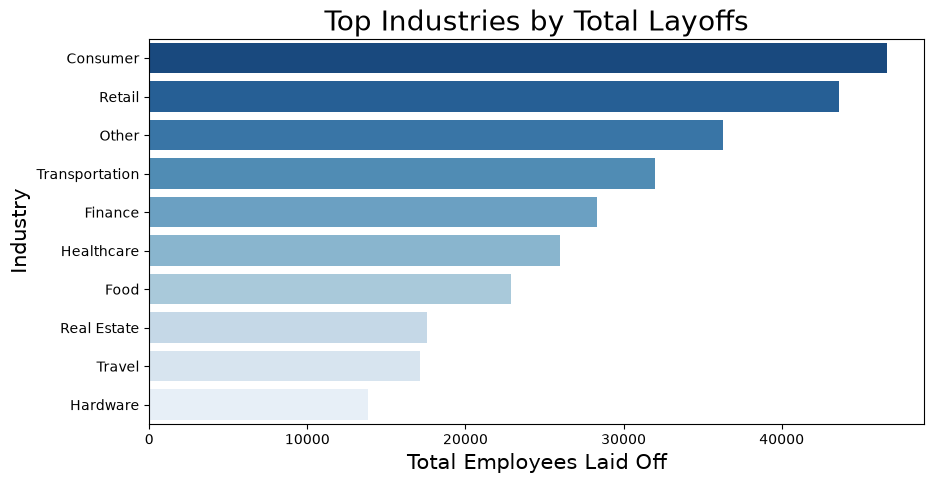

In [10]:
industry_layoffs = (
    df.groupby('industry')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10,5))

sns.barplot(
    data=industry_layoffs,
    x='total_laid_off',
    y='industry',
    palette='Blues_r'
)

plt.title('Top Industries by Total Layoffs', fontsize=20)
plt.xlabel('Total Employees Laid Off', fontsize=15)
plt.ylabel('Industry', fontsize=15)

plt.show()

## Top Companies by Total Layoffs

C:\Users\aumee\AppData\Local\Temp\ipykernel_21612\1667578449.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


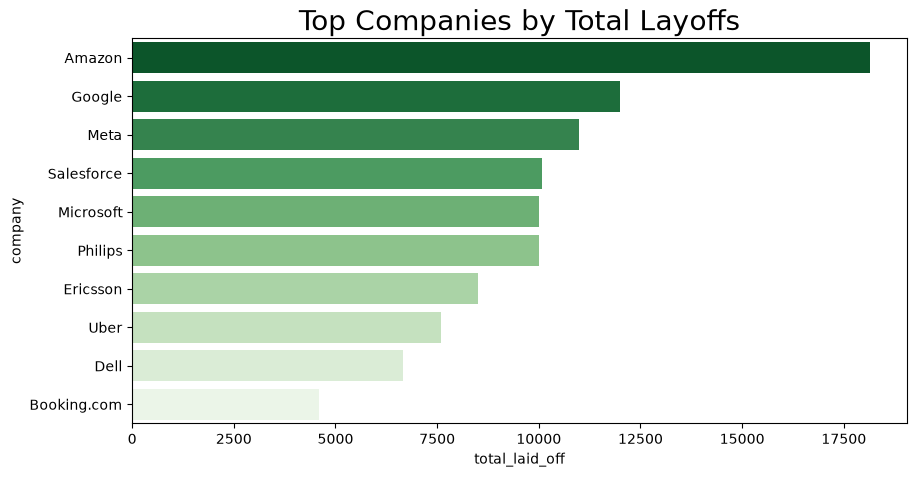

In [11]:
company_layoffs = (
    df.groupby('company')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10,5))

sns.barplot(
    data=company_layoffs,
    x='total_laid_off',
    y='company',
    palette='Greens_r'
)

plt.title('Top Companies by Total Layoffs', fontsize=20)

plt.show()


## Yearly Layoff Trend

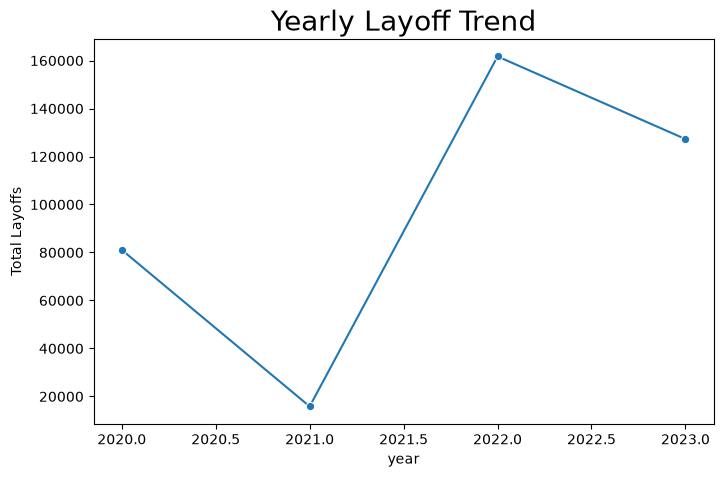

In [12]:
df['year'] = df['date'].dt.year

yearly = (
    df.groupby('year')['total_laid_off']
    .sum()
    .reset_index()
)

plt.figure(figsize=(8,5))

sns.lineplot(
    data=yearly,
    x='year',
    y='total_laid_off',
    marker='o'
)

plt.title('Yearly Layoff Trend', fontsize=20)

plt.ylabel('Total Layoffs')

plt.show()

## Monthly Layoff Trend

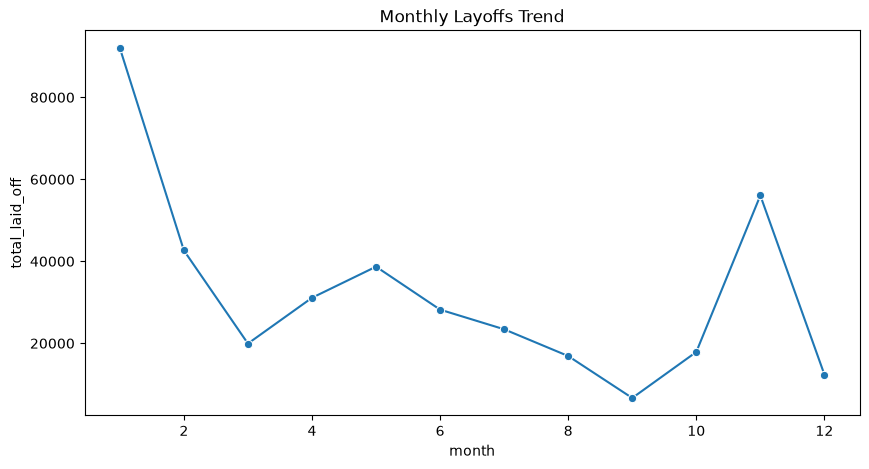

In [13]:
monthly = (
    df.groupby('month')['total_laid_off']
    .sum()
    .reset_index()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    data=monthly,
    x='month',
    y='total_laid_off',
    marker='o'
)

plt.title('Monthly Layoffs Trend')

plt.show()

## Startup Stage Analysis

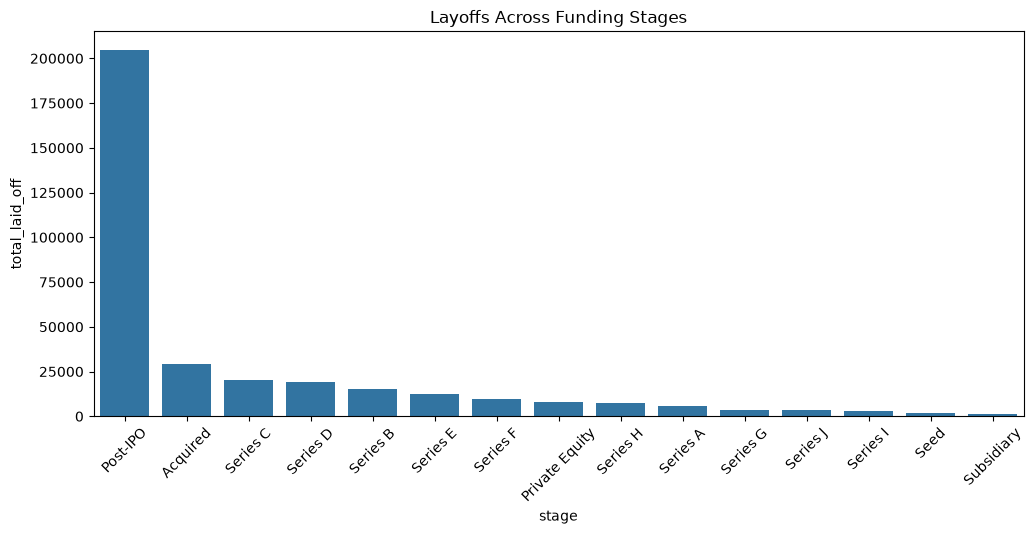

In [14]:
stage_layoffs = (
    df.groupby('stage')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12,5))

sns.barplot(
    data=stage_layoffs,
    x='stage',
    y='total_laid_off'
)

plt.xticks(rotation=45)

plt.title('Layoffs Across Funding Stages')

plt.show()

## Percentage Layoff Distribution

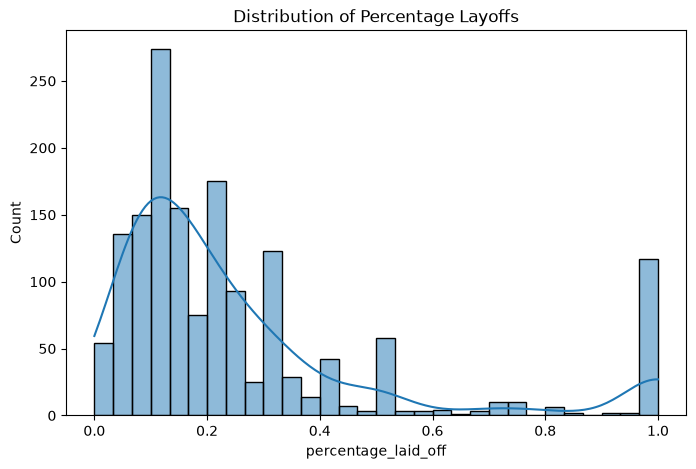

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['percentage_laid_off'],
    bins=30,
    kde=True
)

plt.title('Distribution of Percentage Layoffs')

plt.show()

## Top Locations

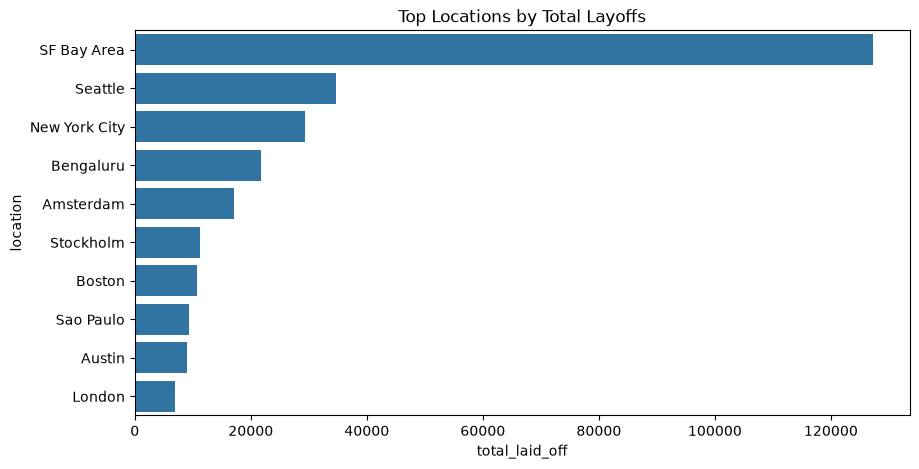

In [16]:
location_layoffs = (
    df.groupby('location')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10,5))

sns.barplot(
    data=location_layoffs,
    x='total_laid_off',
    y='location'
)

plt.title('Top Locations by Total Layoffs')

plt.show()

## Industry vs Year Heatmap ⭐

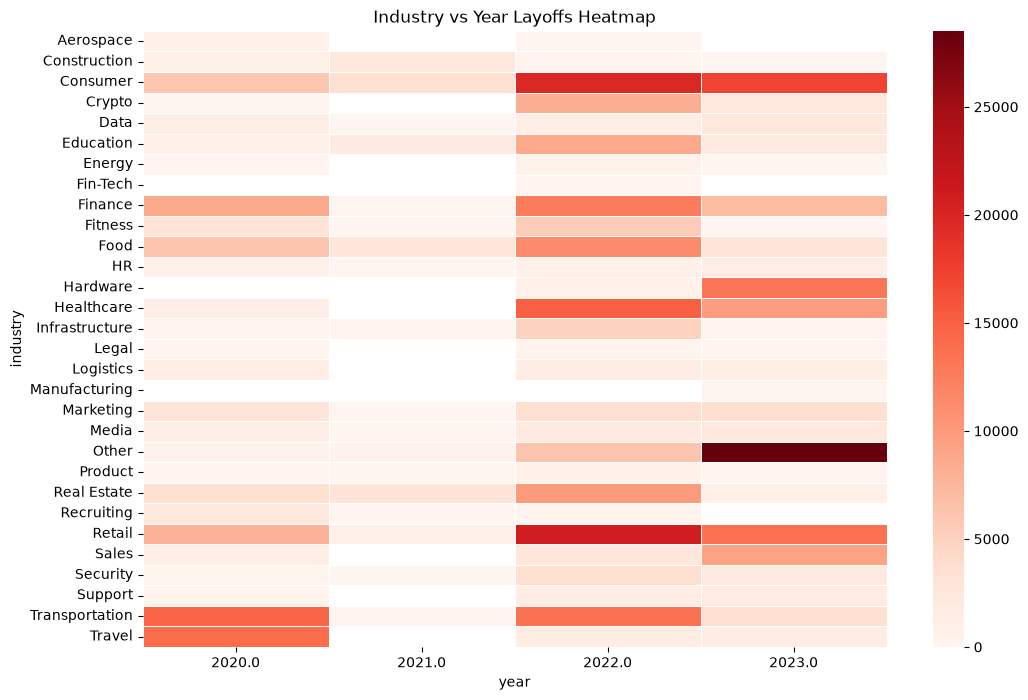

In [17]:
pivot = pd.pivot_table(
    df,
    values='total_laid_off',
    index='industry',
    columns='year',
    aggfunc='sum'
)

plt.figure(figsize=(12,8))

sns.heatmap(
    pivot,
    cmap='Reds',
    linewidths=.5
)

plt.title('Industry vs Year Layoffs Heatmap')

plt.show()

## Correlation Analysis ⭐

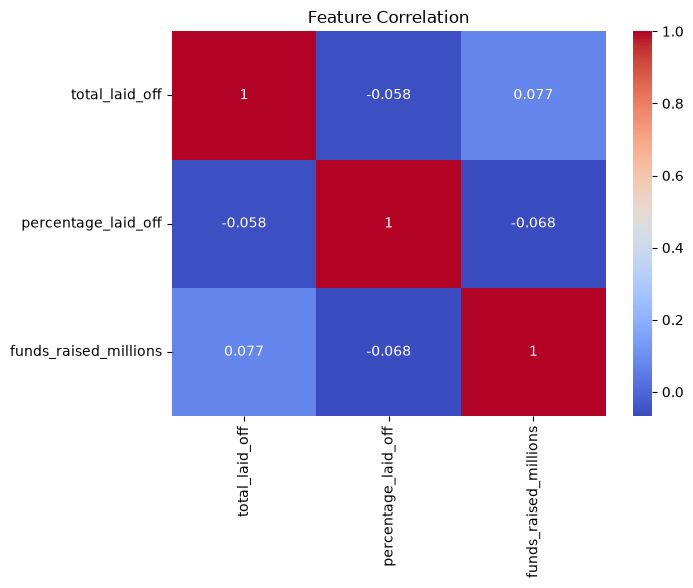

In [18]:
corr = df[
    ['total_laid_off',
     'percentage_laid_off',
     'funds_raised_millions']
].corr()

plt.figure(figsize=(7,5))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Feature Correlation')

plt.show()